# Exercise 1 — A transient on a host galaxy

*Covers notebooks 01–03. Difficulty: ★☆☆☆☆*

A supernova or kilonova sits on a host galaxy whose light adds photon noise and can saturate the nucleus. How faint a transient can the WCC detect, and how much does it depend on where in the galaxy it lands?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import wcc_etc
from wcc_etc import Simulation, get_scene

wcc_etc.set_wcc_style()

### 1.1 — Blank sky

A G5V-like transient on empty sky, observed in zwo:r. What is the 5 sigma limiting magnitude in a
single 300 s exposure? (Use `limiting_mag` from notebook 01, or write your own.)

In [2]:
def limiting_mag(sim, t, snr_target=5, mags=np.arange(16, 32.01, 0.25), **kw):
    """Magnitude at which the SNR in t seconds falls to snr_target; NaN if saturated or not bracketed."""
    r = sim.get_image_snr(t, mags=mags, warn=False, **kw)
    snr = np.where(r["saturated"], np.nan, r["snr"])
    ok = np.isfinite(snr)
    if ok.sum() < 2 or not (snr[ok].max() > snr_target > snr[ok].min()):
        return np.nan
    return float(np.interp(np.log10(snr_target), np.log10(snr[ok][::-1]), mags[ok][::-1]))

blank = Simulation.from_sensorfilter("zwo:r", get_scene("G5V", mag=22, bandpass="sdss_r", magsys="abmag"))
print(f"blank sky, 300 s: 5 sigma at r = {limiting_mag(blank, 300):.2f}")

[wcc_etc] note: even n_pixels is rounded up by 1 to center the PSF peak (shown once).


blank sky, 300 s: 5 sigma at r = 27.03


### 1.2 — On a host

Put the same transient at r = 22, 0.5" from the nucleus of an r = 16 elliptical (Sersic n = 4,
half-light radius 0.5"). What is its SNR in 300 s, and the 5 sigma depth at that position?
Check the saturation flag.

In [3]:
scene = get_scene("G5V", mag=22, bandpass="sdss_r", magsys="abmag",
                  host="G5V", host_prop={"mag": 16, "profile": "sersic", "r_eff": 0.5, "n": 4, "dx": 0.5,
                                         "bandpass": "sdss_r", "magsys": "abmag"})
sim = Simulation.from_sensorfilter("zwo:r", scene)
r = sim.get_image_snr(300, warn=False)
print(f"r = 22 at 0.5\": SNR {r['snr']:.1f}, saturated: {r['saturated']}; 5 sigma depth r = {limiting_mag(sim, 300):.2f}")

r = 22 at 0.5": SNR 92.1, saturated: False; 5 sigma depth r = 25.55


> ✏️ **Before you run the next cell:** the transient now sits on the nucleus (dx = 0). Does the 5 sigma depth drop by 0.5, 1.5 or 3 magnitudes compared with blank sky? Write your guess down (or put it in the room poll), then run.

### 1.3 — Nuclear

Move the transient onto the nucleus. Is a single 300 s frame still unsaturated? Find the smallest
read split that is (`choose_reads` from notebook 02), and the 5 sigma depth with that split.

In [4]:
READS = (1, 2, 3, 6, 10, 30, 60, 120, 240)

def choose_reads(sim, t, reads=READS, **kw):
    """Smallest read count whose per-frame image has no saturated pixel; (None, last result) if none works."""
    for n in reads:
        r = sim.get_image_snr(t, n_reads=n, warn=False, **kw)
        if not np.any(r["saturated"]):
            return n, r
    return None, r

sim.update(host__dx=0.0)
print("single 300 s frame saturated:", sim.get_image_snr(300, warn=False)["saturated"])
n, r = choose_reads(sim, 300)
print(f"smallest split: {n} x {300 / n:.0f} s; 5 sigma depth on the nucleus: r = {limiting_mag(sim, 300, n_reads=n):.2f}")

single 300 s frame saturated: True
smallest split: 2 x 150 s; 5 sigma depth on the nucleus: r = 23.73


### 1.4 — Depth versus offset

Plot the 5 sigma depth in 300 s as a function of the offset from the nucleus (0, 0.25, 0.5, 1,
1.5, 3"), each with its own smallest read split, with the blank-sky depth as a horizontal line.

0.00": 2 reads, 5 sigma at r = 23.73


0.25": 1 reads, 5 sigma at r = 24.91


0.50": 1 reads, 5 sigma at r = 25.55


1.00": 1 reads, 5 sigma at r = 26.23


1.50": 1 reads, 5 sigma at r = 26.58
3.00": 1 reads, 5 sigma at r = 26.94


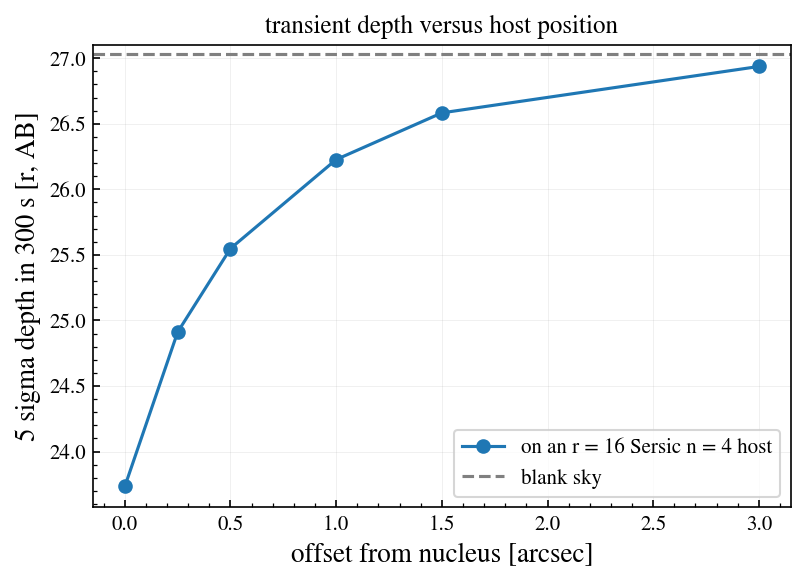

In [5]:
offsets = [0, 0.25, 0.5, 1.0, 1.5, 3.0]
depths = []
for dx in offsets:
    sim.update(host__dx=dx)
    n, _ = choose_reads(sim, 300)
    depths.append(limiting_mag(sim, 300, n_reads=n))
    print(f"{dx:4.2f}\": {n} reads, 5 sigma at r = {depths[-1]:.2f}")
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(offsets, depths, "o-", label="on an r = 16 Sersic n = 4 host")
ax.axhline(limiting_mag(blank, 300), color="0.5", ls="--", label="blank sky")
ax.set(xlabel="offset from nucleus [arcsec]", ylabel="5 sigma depth in 300 s [r, AB]", title="transient depth versus host position")
ax.legend()
plt.show()

### 1.5 — The template

The transient is really measured on a difference image, so the template's noise adds:
$\sigma_\mathrm{diff}^2 = \sigma_\mathrm{sci}^2 + \sigma_\mathrm{ref}^2 / k$ for a template
$k$ times deeper. For the nuclear case, compute the 5 sigma depth with an equal-depth template
($k = 1$) and with one five times deeper. `signal_e` and `noise_e` with `mags=` give the arrays;
the template is the same scene with the transient removed (set its magnitude to 40).

In [6]:
sim.update(host__dx=0.0)
n, sci = choose_reads(sim, 300, mags=np.arange(18, 28.01, 0.25))
mags = np.arange(18, 28.01, 0.25)
for k in (1, 5):
    _, ref = choose_reads(sim, 300 * k, mags=np.full_like(mags, 40.0))
    snr = sci["signal_e"] / np.hypot(sci["noise_e"], ref["noise_e"] / k)
    ok = np.isfinite(snr)
    depth = np.interp(np.log10(5), np.log10(snr[ok][::-1]), mags[ok][::-1])
    print(f"template {k} x deeper: 5 sigma at r = {depth:.2f}")

template 1 x deeper: 5 sigma at r = 23.36
template 5 x deeper: 5 sigma at r = 23.63


> 🤖 **Ask Jupyter AI:** *Explain why the host penalty is largest on the nucleus even when the nucleus is not saturated, and what the half-light radius has to do with it. Then: how would I add an AGN-like power-law host component instead of a G5V spectrum?*

***
## Share-back and feedback

Bring back **one plot and one number** to the share-back board, and the observing decision you draw
from them.

> 🤖 **Ask Jupyter AI:** *Draft a GitHub issue for schmidt-observatories/wcc-etc describing one thing I
> found missing, confusing or wrong in this exercise, with a minimal code example.*